In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

时序分析（LSTM）

第一部分\
描述性统计\
类似summary和ANAI中的内容，看看数据全局特征，看看采集有没有问题。选择1~2台机器可视化查看是否有一些相关性存在。\
略

第二部分\
建模预测

In [6]:
# 加载数据集
DATA_DIR = "./datasets"

errors = pd.read_csv(f"{DATA_DIR}/PdM_errors.csv")
failures = pd.read_csv(f"{DATA_DIR}/PdM_failures.csv")
machines = pd.read_csv(f"{DATA_DIR}/PdM_machines.csv")
maint = pd.read_csv(f"{DATA_DIR}/PdM_maint.csv")
telemetry = pd.read_csv(f"{DATA_DIR}/PdM_telemetry.csv",)

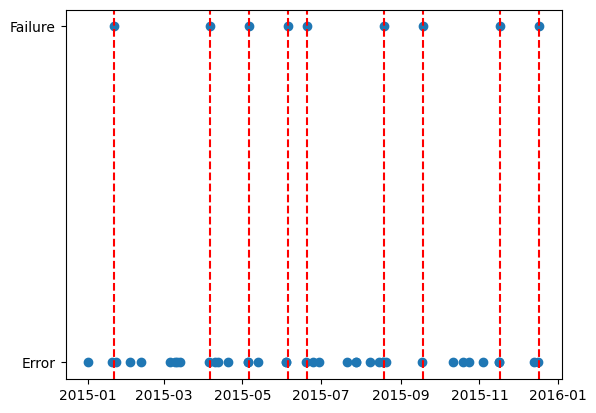

In [7]:
sel_fail = failures.loc[failures['machineID'] == 42].reset_index(drop=True)
sel_err = errors.loc[errors['machineID'] == 42].reset_index(drop=True)

category = list()
for i in range(0, len(sel_fail)):
    category.append('Failure')
for i in range(0, len(sel_err)):
    category.append('Error')

timestap = pd.concat([sel_fail['datetime'], sel_err['datetime']], ignore_index=True, axis=0)

fig, ax = plt.subplots()
plot = pd.DataFrame({"timestap": timestap, "category":category})
plot['timestap'] = pd.to_datetime(plot['timestap'])
plot.sort_values(by=['timestap'], inplace=True, ignore_index=True)

ax.scatter('timestap', 'category', data=plot)

for failure_time in plot[plot['category'] == 'Failure']['timestap'].values:
    ax.axvline(x=failure_time, color='red', linestyle='--')

plt.xticks()
plt.show()

失效发生与故障出现在时间点上重合，但并非每次故障都会导致失效\
\
进一步，选择一个失效发生的时间点，生成其前后7天的时间序列图，初步查看传感器指标是否有显著的异常波动

In [8]:
sel_tel = telemetry[telemetry['machineID'] == 42].reset_index(drop=True)
sel_tel['datetime'] = pd.to_datetime(sel_tel['datetime'])


sel_fail['datetime'] = pd.to_datetime(sel_fail['datetime'])
timepoint = sel_fail.loc[0,'datetime']

start_time = timepoint - pd.Timedelta(days=3)
end_time = timepoint + pd.Timedelta(days=3)

select = sel_tel[(sel_tel['datetime'] >= start_time) & (sel_tel['datetime'] <= end_time)]

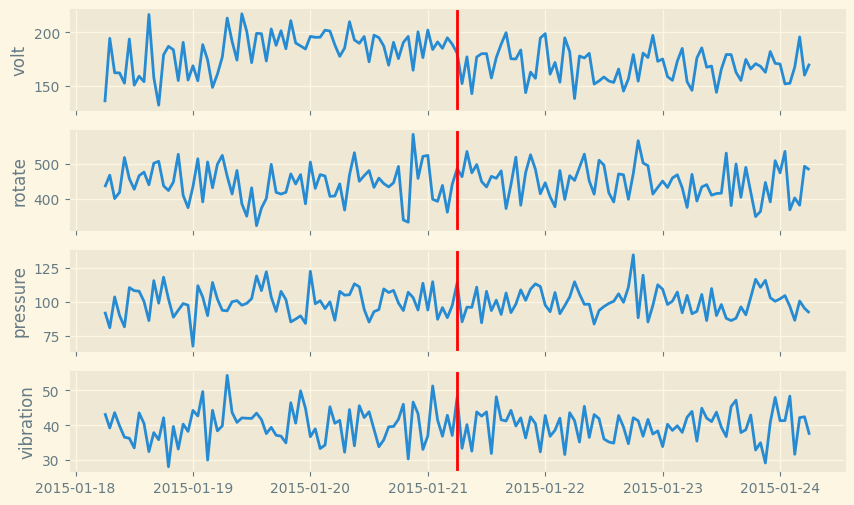

In [9]:
plt.style.use('Solarize_Light2')
fig, ax = plt.subplots(nrows=4, sharex=True, figsize=(10, 6))

ax[0].plot('datetime', 'volt', data=select)
ax[0].axvline(x=timepoint, color='red')
ax[0].set_ylabel('volt')

ax[1].plot('datetime', 'rotate', data=select)
ax[1].axvline(x=timepoint, color='red')
ax[1].set_ylabel('rotate')

ax[2].plot('datetime', 'pressure', data=select)
ax[2].axvline(x=timepoint, color='red')
ax[2].set_ylabel('pressure')

ax[3].plot('datetime', 'vibration', data=select)
ax[3].axvline(x=timepoint, color='red')
ax[3].set_ylabel('vibration')

plt.show()

rotate和Vibration在发生时点前波动是比较大的，volt和pressure则是波动较小
volt在失效之后整体电压水平较之前有所下降
rotate在失效之前出现了一次大幅度的波动
pressur在失效前后没有太明显的编号
vibration在失效之前也出现了一次大幅度的波动
volt可能是失效导致的结果，暂时易rotate和vibration作为主要特征进行查看\
\
查看rotate和vibration的自相关和偏自相关图

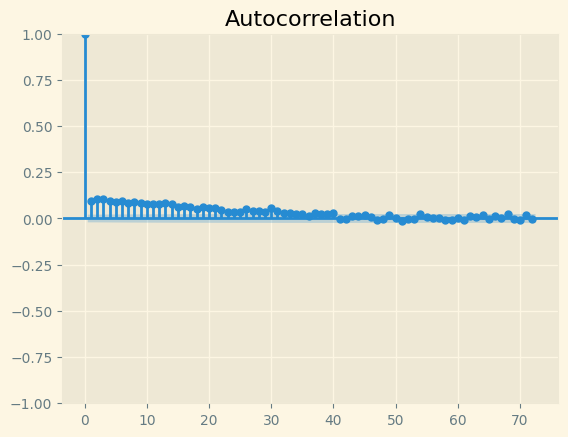

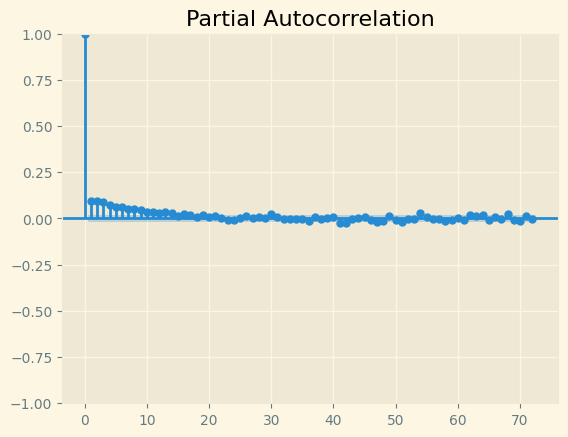

In [10]:
plot_acf(sel_tel['rotate'], lags=72)
plt.show()
plot_pacf(sel_tel['rotate'], lags=72)
plt.show()

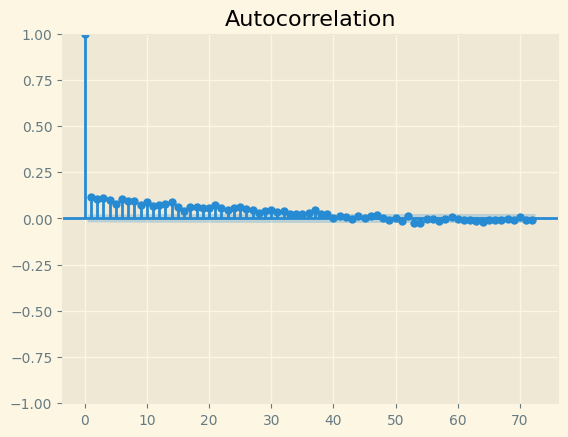

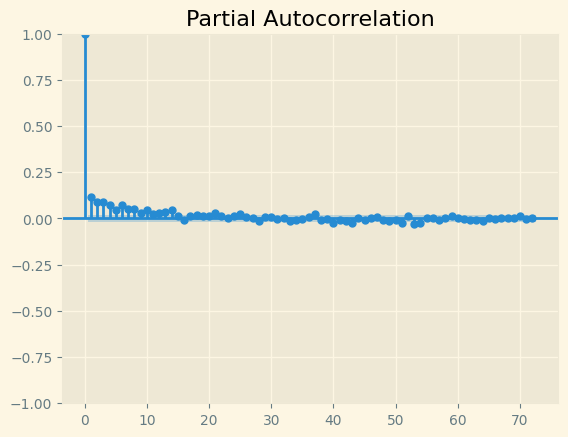

In [11]:
plot_acf(sel_tel['vibration'], lags=72)
plt.show()
plot_pacf(sel_tel['vibration'], lags=72)
plt.show()

都没有明显的拖尾

用LSTM建模

In [13]:
# preprocess
telemetry['datetime'] = pd.to_datetime(telemetry['datetime'])
telemetry.sort_values(['datetime', 'machineID'], inplace=True)
telemetry.reset_index(drop=True, inplace=True)

failures['datetime'] = pd.to_datetime(failures['datetime'])
failures.sort_values(['datetime', 'machineID'], inplace=True)
failures.reset_index(drop=True, inplace=True)
failures['failure_datetime'] = failures['datetime']

dataset = pd.merge_asof(telemetry, failures, 
                        on='datetime',
                        by='machineID',
                        suffixes=('_tel', '_fail'),
                        direction='forward').sort_values(['machineID', 'datetime'])
dataset['RUL'] = dataset['failure_datetime'] - dataset['datetime']
dataset.reset_index(drop=True, inplace=True)